# Flight Delay Prediction: American Airlines

In this notebook we build a model that predicts whether an **American Airlines (AA)** domestic flight will be delayed.

We use data from the **Bureau of Transportation Statistics (BTS)**, the *Reporting Carrier On-Time Performance* dataset. It has one row per US domestic flight, and we use all of 2025 (January–December).

## 1. Introduction

### Business question
> *"Can American Airlines' operations team use ML to predict flight delays (>15 min) before departure for proactive resource allocation?"*

Delays are expensive. A study funded by the FAA (Ball et al., 2010) estimated that flight delays cost the US economy **about $33 billion a year**. The costs land on airlines (crew, fuel, maintenance), on passengers (lost time) and on the wider economy.

If the operations team knows a flight is likely to be delayed, they can act before it happens. For example, they can have a spare aircraft or crew ready, move gate staff, or rebook passengers with tight connections.

### ML question
> *"Can we predict whether an American Airlines flight will arrive more than 15 minutes late, using only information available 2 hours before departure?"*

This is a **binary classification** problem:

- Each row is one scheduled AA flight.
- The target is `Delayed`. It is `1` if the flight arrives more than 15 minutes late (the official US Department of Transportation definition) and `0` otherwise.
- We make the prediction **2 hours before departure**. So we can only use what is known at that point: the schedule (date, time, route, distance), which aircraft is assigned (`Tail_Number`) and historical patterns. Anything we only learn at or after departure is off limits.

### Imports
All libraries are imported here in one place.

In [10]:
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from fairlearn.metrics import (
    MetricFrame,
    false_positive_rate,
    selection_rate,
    true_positive_rate,
)
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Consistent colour palette for all plots
COLOR_DELAYED = "#eb6834"  # orange: delayed
COLOR_ONTIME = "#2a78d6"   # blue: on time
COLOR_REF = "#8a8984"      # grey: reference line

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#ecebe7",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

RANDOM_STATE = 42

## 2. Data Loading & Cleaning

### 2.1 Download the raw data

BTS publishes one zip file per month. The cell below goes through all 12 months of 2025 and:

1. Downloads the zip file to `data/`, unless we already have it.
2. Reads the CSV file inside it with **all** of its columns (more than 100).
3. Keeps only the columns we need.

We do the column selection month by month. Loading all columns for 7 million flights at once would not fit in memory on a normal laptop.

These are the columns we keep:

| Column | Why we keep it |
|---|---|
| `FlightDate`, `Month`, `DayOfWeek`, `CRSDepTime` | When the flight is scheduled. Known in advance |
| `Origin`, `Dest`, `Distance` | The route. Known in advance |
| `Tail_Number` | Which aircraft flies it. Known 2 hours before departure |
| `Reporting_Airline` | So we can filter to AA |
| `Cancelled`, `Diverted` | So we can remove flights that never arrived |
| `ArrDelay` | To build the target |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Reasons for the delay. Used **only for exploration**, never as features |

In [11]:
YEAR = 2025
MONTHS = range(1, 13)
URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

DELAY_CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "LateAircraftDelay", "SecurityDelay"]
COLUMNS = [
    "FlightDate", "Month", "DayOfWeek", "Origin", "Dest", "CRSDepTime",
    "ArrDelay", "Cancelled", "Diverted", "Distance", "Tail_Number",
    *DELAY_CAUSES, "Reporting_Airline",
]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

monthly_frames = []

for month in MONTHS:
    url = URL_TEMPLATE.format(year=YEAR, month=month)
    zip_path = DATA_DIR / f"ontime_{YEAR}_{month:02d}.zip"

    # 1) Download (only if we don't already have the file)
    if not zip_path.exists():
        print(f"Downloading {url} ...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

    # 2) Read the CSV file directly from the zip, with all columns
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df_month = pd.read_csv(f, low_memory=False)

    print(f"{YEAR}-{month:02d}: {len(df_month):,} rows, {df_month.shape[1]} columns available")

    # 3) Keep only the columns we need
    monthly_frames.append(df_month[COLUMNS])

# 4) Combine all months into one DataFrame
raw = pd.concat(monthly_frames, ignore_index=True)
print(f"\nTotal: {len(raw):,} flights (all airlines), {raw.shape[1]} columns selected")

2025-01: 539,747 rows, 110 columns available
2025-02: 504,884 rows, 110 columns available
2025-03: 600,872 rows, 110 columns available
2025-04: 583,950 rows, 110 columns available
2025-05: 605,648 rows, 110 columns available
2025-06: 611,575 rows, 110 columns available
2025-07: 631,428 rows, 110 columns available
2025-08: 602,378 rows, 110 columns available
2025-09: 562,439 rows, 110 columns available
2025-10: 605,844 rows, 110 columns available
2025-11: 570,550 rows, 110 columns available
2025-12: 582,304 rows, 110 columns available

Total: 7,001,619 flights (all airlines), 17 columns selected


### 2.2 Keep only American Airlines

The dataset covers every US airline. We keep only AA's flights. After that, every row has the same airline, so we drop the `Reporting_Airline` column.

In [12]:
df = raw[raw["Reporting_Airline"] == "AA"].drop(columns=["Reporting_Airline"])

print(f"AA flights: {len(df):,} of {len(raw):,} ({len(df) / len(raw):.1%})")

AA flights: 973,653 of 7,001,619 (13.9%)


### 2.3 Remove cancelled and diverted flights

A cancelled flight never takes off, and a diverted flight lands somewhere else. Neither has a real arrival delay, so we can't say whether they were "late". We remove them.

After that, the `Cancelled` and `Diverted` columns only contain 0, so we drop them too.

In [13]:
n_before = len(df)

df = df[(df["Cancelled"] != 1) & (df["Diverted"] != 1)]
df = df.drop(columns=["Cancelled", "Diverted"])

print(f"Removed {n_before - len(df):,} cancelled/diverted flights")
print(f"Remaining: {len(df):,} rows")

Removed 20,812 cancelled/diverted flights
Remaining: 952,841 rows


### 2.4 Remove rows with no arrival delay

We build the target from `ArrDelay`. If it is missing, we can't tell whether the flight was late, so we drop the row.

In [14]:
n_before = len(df)

df = df.dropna(subset=["ArrDelay"]).reset_index(drop=True)

print(f"Removed {n_before - len(df):,} rows with missing ArrDelay")
print(f"Remaining: {len(df):,} rows")

Removed 0 rows with missing ArrDelay
Remaining: 952,841 rows


### 2.5 Create the target: `Delayed`

We use the official definition: a flight is delayed if it arrives **more than 15 minutes** after its scheduled time.

- `Delayed = 1`: delayed (`ArrDelay > 15`)
- `Delayed = 0`: on time

In [15]:
df["Delayed"] = (df["ArrDelay"] > 15).astype(int)

### 2.6 Avoid cheating: target leakage

Our model has to predict 2 hours before departure. So it may only use information we actually have at that point. If it uses information from the future, it will look great in testing and fail in practice. This is called **target leakage**. Kapoor & Narayanan (2023) show it is one of the most common mistakes in machine learning projects.

Two groups of columns would leak the answer:

- **`ArrDelay` is the answer itself.** If we know how late a flight arrived, we already know whether it was delayed.
- **The delay cause columns** (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay`) are only filled in after the flight lands, and only when it was delayed. Using them would be cheating.

The delay causes are still useful for *understanding* delays, for example how many are caused by a late incoming aircraft. So we move them, together with `ArrDelay`, into a separate DataFrame called `delay_causes` for the exploration later. Then we remove them from the main dataset, so they can't end up as features by accident.

In [16]:
# Separate DataFrame for EDA: same index as df, so they can be joined again
delay_causes = df[["ArrDelay", *DELAY_CAUSES]].copy()

# Remove the leakage columns from the main dataset
df = df.drop(columns=["ArrDelay", *DELAY_CAUSES])

print("delay_causes:", delay_causes.shape)
print("df:          ", df.shape)
print("Columns in df:", list(df.columns))

delay_causes: (952841, 6)
df:           (952841, 9)
Columns in df: ['FlightDate', 'Month', 'DayOfWeek', 'Origin', 'Dest', 'CRSDepTime', 'Distance', 'Tail_Number', 'Delayed']


### 2.7 Strengths and limitations of the data

What the data does well:
- It contains every AA domestic flight in 2025, not a sample.
- It is an official source with the same definitions everywhere.
- A full year covers all seasons: winter storms, summer peaks and holidays.
- About 950,000 flights is plenty for training and testing.
- `Tail_Number` lets us follow each aircraft through its day.

What it can't tell us:
- There is no weather data, even though weather causes many delays.
- It only covers one year, so we can't check whether patterns hold in 2026.
- Removing cancelled flights hides the worst days, because cancellations cluster on bad days.
- International flights are not included.
- There is no operational data, such as passenger numbers, staffing or maintenance.
- It is observational data. We can find patterns, but not prove what causes delays.

### 2.8 Class balance

How many flights are delayed compared with on time?

This matters because accuracy can be misleading when the classes are uneven. A model that always says "on time" would be right most of the time and still be useless. We will handle this later with class weights and metrics such as ROC-AUC and PR-AUC.

              Count  Share
On time (0)  714611  75.0%
Delayed (1)  238230  25.0%


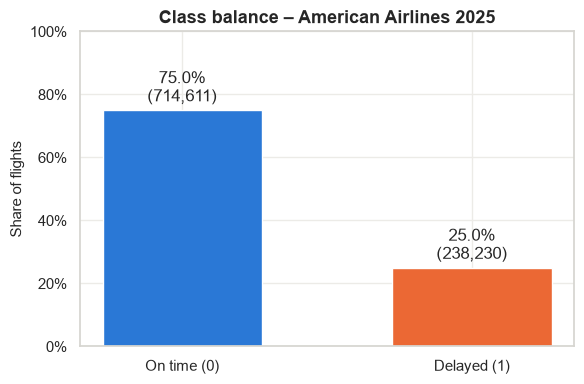

In [17]:
counts = df["Delayed"].value_counts().sort_index()
shares = counts / counts.sum()

balance = pd.DataFrame({"Count": counts, "Share": shares.map("{:.1%}".format)})
balance.index = ["On time (0)", "Delayed (1)"]
print(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, shares.values, color=[COLOR_ONTIME, COLOR_DELAYED], width=0.55)
ax.bar_label(bars, labels=[f"{s:.1%}\n({c:,})" for s, c in zip(shares, counts)], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_ylabel("Share of flights")
ax.set_title("Class balance – American Airlines 2025")
plt.tight_layout()
plt.show()

### 2.9 Save the cleaned dataset

We save the result as `cleaned_flights_aa.csv`. That way the next sections can start from here without downloading and cleaning everything again.

In [18]:
df.to_csv("cleaned_flights_aa.csv", index=False)

print(f"Saved cleaned_flights_aa.csv ({len(df):,} rows, {df.shape[1]} columns)")
display(df.head())

Saved cleaned_flights_aa.csv (952,841 rows, 9 columns)


,FlightDate,Month,DayOfWeek,Origin,Dest,CRSDepTime,Distance,Tail_Number,Delayed
0,2025-01-01,1,3,JFK,LAX,659,2475.0,N104NN,0
1,2025-01-02,1,4,JFK,LAX,659,2475.0,N110AN,0
2,2025-01-03,1,5,JFK,LAX,659,2475.0,N106NN,0
3,2025-01-04,1,6,JFK,LAX,700,2475.0,N117AN,0
4,2025-01-05,1,7,JFK,LAX,659,2475.0,N104NN,0
